# Heavy Equipment Selling Price Prediction

Objective : Predict the selling price of heavy equipment using machine learning models.

Evaluation Metric:
- RMSLE (Root Mean Squared Log Error)

Approach:
- Exploratory Data Analysis
- Data Preprocessing
- Feature Engineering
- Multiple ML Models
- Model Comparison
- Ensemble

In [1]:
# =====================================================
# Import Required Libraries
# =====================================================

# Data Manipulation
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold
from sklearn.metrics import root_mean_squared_log_error
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from xgboost import XGBRegressor

import lightgbm as lgb
import re
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import LabelEncoder


# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Display Options
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

## 1. Data Loading 


In [2]:
train = pd.read_csv("/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv",low_memory=False)
test = pd.read_csv("/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv",low_memory=False)
metadata = pd.read_csv("/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/metadata.csv")
sample_submission = pd.read_csv("/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/sample_submission.csv")

## 2. First Look at Data

In [3]:
# Step 1 in first look in the data
print(train.shape)
print(test.shape)
print(metadata.shape)

(138701, 50)
(15000, 49)
(50, 2)


In [4]:
# Step 2 in first look
train.head()

,TransactionID,TargetValue,AssetID,ProductConfigID,DataOriginCode,VendorPartnerID,ManufactureYear,OperationalHoursMeter,UtilizationTier,TransactionDate,Spec_FullDescriptor,Spec_BaseClass,Spec_SubClass,Spec_ReleaseSeries,Spec_VariantModifier,AssetScaleFactor,FunctionalClassification,RegionCode,InventoryGroupCategory,InventoryGroupDescription,col1,CabinType,Forks,col3,col4,DrivetrainType,col5,col6,col7,col8,col9,col10,col11,col12,col13,col14,col15,col16,col18,col19,col20,col21,col22,col23,col24,col25,col27,col28,col29,col30
0,1139309,57000.0,117665,88,ACH138,GTX,1997,4640.0,Low,2005-03-26,950FII,950,F,II,NaN,Medium,Wheel Loader - 150.0 to 175.0 Horsepower,North Carolina,WL,Wheel Loader,NaN,EROPS w AC,None or Unspecified,None or Unspecified,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2 Valve,NaN,NaN,NaN,NaN,23.5,None or Unspecified,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Standard,Conventional
1,1139316,26500.0,1001282,4616,ACH138,GTX,2005,508.0,Low,2009-12-18,310G,310,G,NaN,NaN,NaN,Backhoe Loader - 14.0 to 15.0 Ft Standard Digg...,Arizona,BL,Backhoe Loaders,Four Wheel Drive,OROPS,None or Unspecified,No,Extended,Powershuttle,None or Unspecified,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1139317,21000.0,772709,1948,ACH138,GTX,1994,11540.0,High,2005-08-26,790ELC,790,E,NaN,LC,Large / Medium,"Hydraulic Excavator, Track - 21.0 to 24.0 Metr...",Florida,TEX,Track Excavators,NaN,EROPS,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Standard,NaN,NaN,NaN,NaN,NaN,None or Unspecified,NaN,NaN,Steel,None or Unspecified,None or Unspecified,None or Unspecified,None or Unspecified,Double,NaN,NaN,NaN,NaN
3,1139322,27000.0,902010,3550,ACH138,GTX,2002,4883.0,High,2006-11-17,416D,416,D,NaN,NaN,NaN,Backhoe Loader - 14.0 to 15.0 Ft Standard Digg...,Illinois,BL,Backhoe Loaders,Four Wheel Drive,OROPS,None or Unspecified,No,Standard,Standard,Yes,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1139333,21500.0,1036259,36014,ACH138,GTX,2009,302.0,Low,2010-08-27,430HAG,430,HAG,NaN,NaN,Mini,"Hydraulic Excavator, Track - 3.0 to 4.0 Metric...",Texas,TEX,Track Excavators,NaN,EROPS,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Auxiliary,NaN,NaN,NaN,NaN,NaN,Manual,NaN,NaN,Rubber,None or Unspecified,None or Unspecified,None or Unspecified,None or Unspecified,Double,NaN,NaN,NaN,NaN


In [5]:
# Step 3 Check data types of the columns
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 138701 entries, 0 to 138700
Data columns (total 50 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   TransactionID              138701 non-null  int64  
 1   TargetValue                138701 non-null  float64
 2   AssetID                    138701 non-null  int64  
 3   ProductConfigID            138701 non-null  int64  
 4   DataOriginCode             138701 non-null  object 
 5   VendorPartnerID            138701 non-null  object 
 6   ManufactureYear            138701 non-null  int64  
 7   OperationalHoursMeter      82058 non-null   float64
 8   UtilizationTier            50475 non-null   object 
 9   TransactionDate            138701 non-null  object 
 10  Spec_FullDescriptor        138701 non-null  object 
 11  Spec_BaseClass             138701 non-null  object 
 12  Spec_SubClass              101716 non-null  object 
 13  Spec_ReleaseSeries         32

In [6]:
num_cols = train.select_dtypes(include=np.number).columns
len(num_cols)

6

In [7]:
cat_cols = train.select_dtypes(exclude=np.number).columns
len(cat_cols)

44

## Insights #1
1. The training data is 138k rows. Also 49 features are used to predict the price of the machine.
2. Last columns of the training data, by observations they have a lot of NaN values.
3. By looking at the data types of the columns. The dataset is categorical heavy columns. 44 categorical cols, 6 numeric ones

## 3. Exploratory Data Analysis (EDA)

In [8]:
# Step 4 check for missing values in cols
train.isnull().sum()

TransactionID                     0
TargetValue                       0
AssetID                           0
ProductConfigID                   0
DataOriginCode                    0
VendorPartnerID                   0
ManufactureYear                   0
OperationalHoursMeter         56643
UtilizationTier               88226
TransactionDate                   0
Spec_FullDescriptor               0
Spec_BaseClass                    0
Spec_SubClass                 36985
Spec_ReleaseSeries           105805
Spec_VariantModifier          86369
AssetScaleFactor              41210
FunctionalClassification          0
RegionCode                        0
InventoryGroupCategory            0
InventoryGroupDescription         0
col1                         104915
CabinType                         0
Forks                        109382
col3                         109448
col4                         128320
DrivetrainType                89956
col5                         128320
col6                        

In [9]:
# finding % missing values in the dataset. 

missing = (
    train.isnull()
    .mean()
    .sort_values(ascending=False)
)

missing.head(20)

col19                 0.999524
col18                 0.999524
col5                  0.925156
col4                  0.925156
col27                 0.892149
col28                 0.892149
col29                 0.863938
col30                 0.863938
col13                 0.831256
col14                 0.831256
col7                  0.831256
col6                  0.831256
col9                  0.831256
col8                  0.831256
col11                 0.831256
col3                  0.789093
Forks                 0.788617
Spec_ReleaseSeries    0.762828
col1                  0.756411
col12                 0.723405
dtype: float64

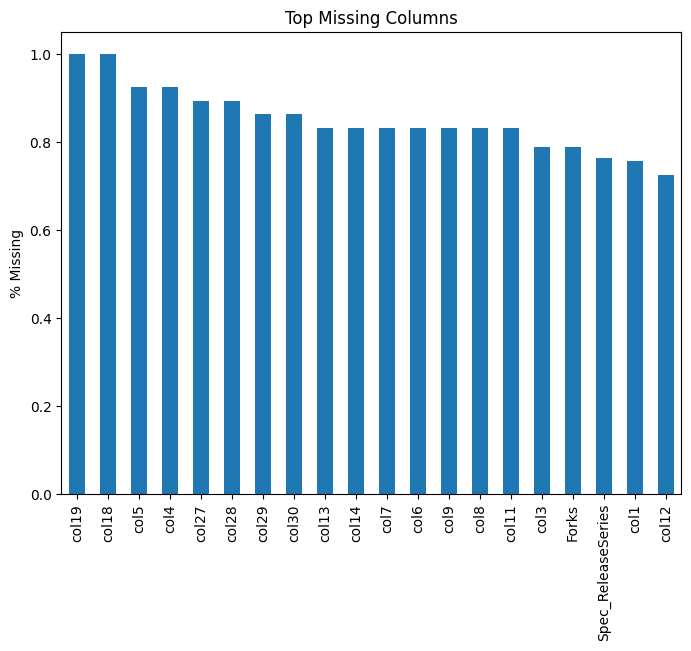

In [10]:
plt.figure(figsize=(8,6))

missing.head(20).plot(kind="bar")

plt.title("Top Missing Columns")
plt.ylabel("% Missing")

plt.show()

In [11]:
# Step 5 summary of numerical columns
train.describe().T

,count,mean,std,min,25%,50%,75%,max
TransactionID,138701.0,2.186276e+06,1.128497e+06,1139309.0,1465754.0,1751884.0,2372139.0,6333410.0
TargetValue,138701.0,4.152187e+04,2.636113e+04,7500.0,20500.0,35000.0,57000.0,142000.0
AssetID,138701.0,1.204814e+06,5.287376e+05,8.0,1007930.0,1246956.0,1495817.0,2478476.0
ProductConfigID,138701.0,7.286422e+03,7.542422e+03,39.0,1693.0,3852.0,11873.0,37209.0
ManufactureYear,138701.0,1.891641e+03,3.069920e+02,1001.0,1990.0,1998.0,2004.0,2015.0
OperationalHoursMeter,82058.0,4.553719e+03,2.792204e+04,0.0,0.0,1620.0,5001.0,1729600.0


In [12]:
#step 6 check duplicate rows 
train.duplicated().sum()


np.int64(0)

## Insights #2
1. there are a lot of columns with null values. Some columns with more than 90% null value.
2.  Target Price varies from 7500.0	to 142000 which justifies the choice of RMSLE. 

In [13]:
# Step 7 check correlation
train.corr(numeric_only=True)

,TransactionID,TargetValue,AssetID,ProductConfigID,ManufactureYear,OperationalHoursMeter
TransactionID,1.000000,-0.012093,0.373844,0.129477,0.065617,0.008129
TargetValue,-0.012093,1.000000,-0.238719,0.057265,0.204439,0.001994
AssetID,0.373844,-0.238719,1.000000,0.154943,-0.029941,0.003505
ProductConfigID,0.129477,0.057265,0.154943,1.000000,-0.009438,-0.013551
ManufactureYear,0.065617,0.204439,-0.029941,-0.009438,1.000000,-0.008256
OperationalHoursMeter,0.008129,0.001994,0.003505,-0.013551,-0.008256,1.000000


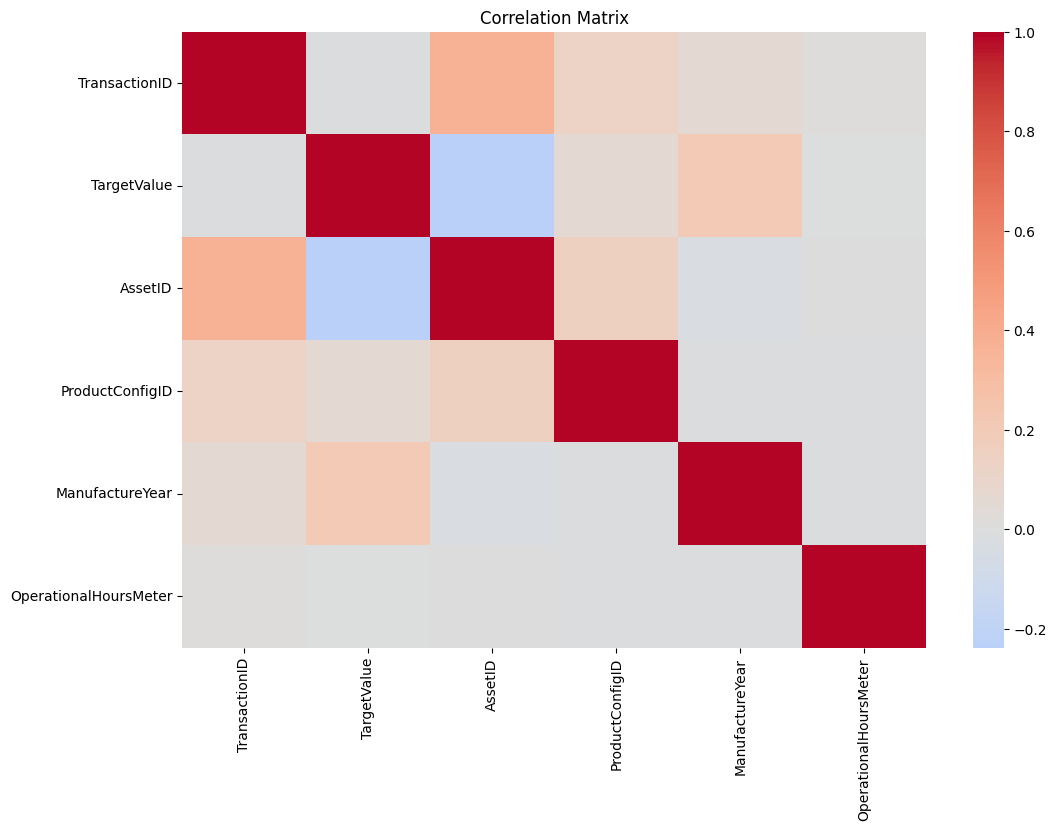

In [14]:
plt.figure(figsize=(12,8))

corr_matrix = train.corr(numeric_only=True)

sns.heatmap(corr_matrix,
            cmap="coolwarm",
            center=0 
           )
#Blue → negative correlation , White → around 0 , Red → positive correlation
#Treat 0 as the middle of the color scale.

plt.title("Correlation Matrix")

plt.show()

In [15]:
train.corr(numeric_only=True)["TargetValue"].sort_values(ascending=False)

TargetValue              1.000000
ManufactureYear          0.204439
ProductConfigID          0.057265
OperationalHoursMeter    0.001994
TransactionID           -0.012093
AssetID                 -0.238719
Name: TargetValue, dtype: float64

In [16]:
train.corr(numeric_only=True)["TargetValue"].abs().sort_values(ascending=False)

TargetValue              1.000000
AssetID                  0.238719
ManufactureYear          0.204439
ProductConfigID          0.057265
TransactionID            0.012093
OperationalHoursMeter    0.001994
Name: TargetValue, dtype: float64

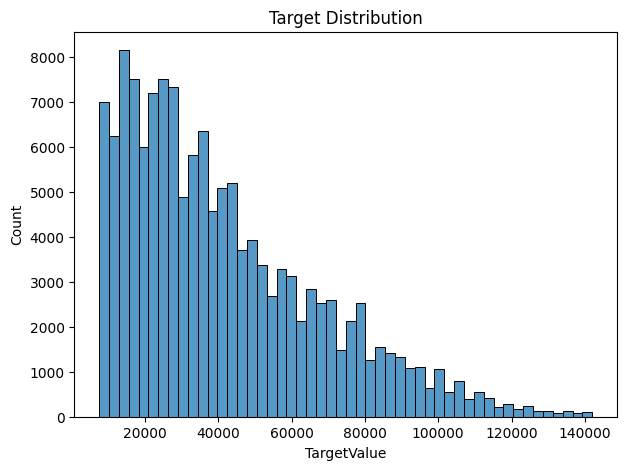

In [17]:
plt.figure(figsize=(7,5))

sns.histplot(train["TargetValue"], bins=50)

plt.title("Target Distribution")

plt.show()

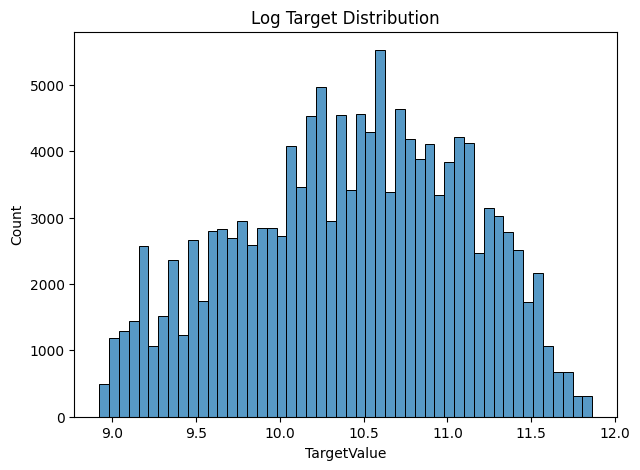

In [18]:
plt.figure(figsize=(7,5))

sns.histplot(np.log1p(train["TargetValue"]), bins=50)

plt.title("Log Target Distribution")

plt.show()

In [19]:
print("Target Value Skewness:", train["TargetValue"].skew())
print(f"Log Target Value Skewness: {np.log1p(train['TargetValue']).skew()}")

Target Value Skewness: 0.9699963984208283
Log Target Value Skewness: -0.19830390386050986


## Insight #3
1. AssetID, ManufactureYear linearly correlated to Price of the machine.
2. The target variable (TargetValue) has a highly uneven distribution. Applying a log transformation reduces this skewness and makes the distribution more balanced.

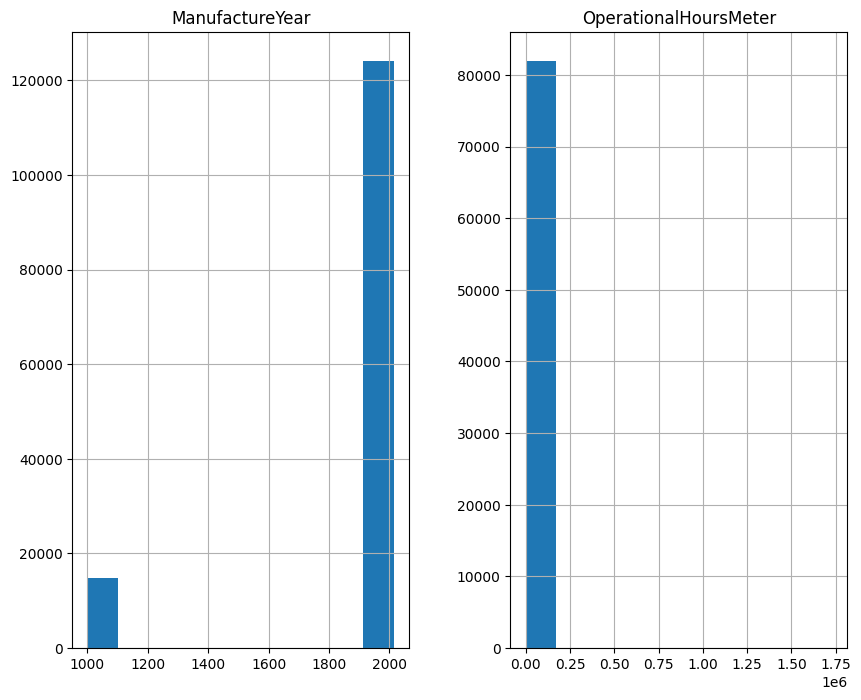

In [20]:
cols = [
    "ManufactureYear",
    "OperationalHoursMeter"
]

train[cols].hist(figsize=(10,8))

plt.show()

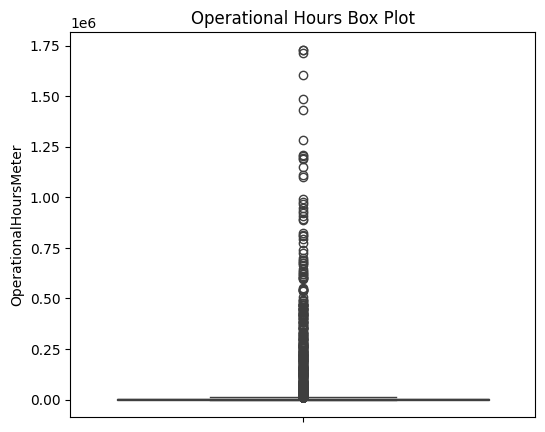

In [21]:
plt.figure(figsize=(6,5))

sns.boxplot(y=train["OperationalHoursMeter"])

plt.title("Operational Hours Box Plot")

plt.show()

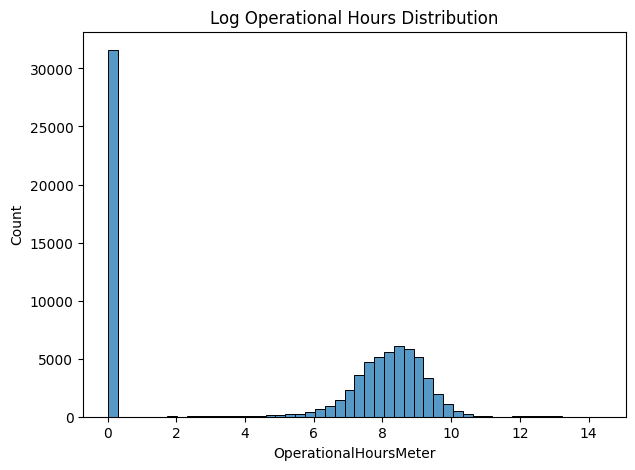

In [22]:
plt.figure(figsize=(7,5))

sns.histplot(np.log1p(train["OperationalHoursMeter"]), bins=50)

plt.title("Log Operational Hours Distribution")

plt.show()

In [23]:
print(train["OperationalHoursMeter"].std())
print(train["OperationalHoursMeter"].min())
print(train["OperationalHoursMeter"].max())

27922.044849863112
0.0
1729600.0


## Insight #4
OperationalHoursMeter is highly right-skewed with extreme outliers (max ~1.7M hours), indicating a few machines have unusually high usage;

## 4. Preprocessing


### 4.1 Remove Uninformative Columns

In [24]:
# finding % missing values in the dataset. 

missing = (
    train.isnull()
    .mean()
    .sort_values(ascending=False)
)

missing.head(20)

col19                 0.999524
col18                 0.999524
col5                  0.925156
col4                  0.925156
col27                 0.892149
col28                 0.892149
col29                 0.863938
col30                 0.863938
col13                 0.831256
col14                 0.831256
col7                  0.831256
col6                  0.831256
col9                  0.831256
col8                  0.831256
col11                 0.831256
col3                  0.789093
Forks                 0.788617
Spec_ReleaseSeries    0.762828
col1                  0.756411
col12                 0.723405
dtype: float64

In [25]:
# Remove the columns with more than 85% missing values. 

def drop_unused_columns(df):
    df = df.copy()

    drop_cols = [
        "col19", "col18",
        "col4", "col5",
        "col28", "col27",
        "col30", "col29"
    ]

    return df.drop(columns=drop_cols)

train = drop_unused_columns(train)
test = drop_unused_columns(test)

In [26]:
# 1. Replacing 1001 with NaN
train["ManufactureYear"] = train["ManufactureYear"].replace(1001, np.nan)
test["ManufactureYear"] = test["ManufactureYear"].replace(1001, np.nan)

### 4.2 Numerical Missing Value Imputation not mandatory as we are using cat,xg, light bgm models

In [27]:
def process_dates(df):
    df = df.copy()
    df["TransactionDate"] = pd.to_datetime(df["TransactionDate"])
    df["TransactionYear"] = df["TransactionDate"].dt.year
    df["TransactionMonth"] = df["TransactionDate"].dt.month
    df["TransactionDay"] = df["TransactionDate"].dt.day
    df["TransactionDayOfWeek"] = df["TransactionDate"].dt.dayofweek
    df["TransactionQuarter"] = df["TransactionDate"].dt.quarter
    df["MachineAge"] = (
        df["TransactionYear"] - df["ManufactureYear"]
    )

    df.drop(columns=["TransactionDate"], inplace=True)

    return df

train = process_dates(train)
test = process_dates(test)

In [28]:
num_cols = train.select_dtypes(include=np.number).columns
train[num_cols].isna().sum()

TransactionID                0
TargetValue                  0
AssetID                      0
ProductConfigID              0
ManufactureYear          14719
OperationalHoursMeter    56643
TransactionYear              0
TransactionMonth             0
TransactionDay               0
TransactionDayOfWeek         0
TransactionQuarter           0
MachineAge               14719
dtype: int64

### 4.3 Categorical Cols

In [29]:
cat_cols = train.select_dtypes(include="object").columns
cat_cols

Index(['DataOriginCode', 'VendorPartnerID', 'UtilizationTier',
       'Spec_FullDescriptor', 'Spec_BaseClass', 'Spec_SubClass',
       'Spec_ReleaseSeries', 'Spec_VariantModifier', 'AssetScaleFactor',
       'FunctionalClassification', 'RegionCode', 'InventoryGroupCategory',
       'InventoryGroupDescription', 'col1', 'CabinType', 'Forks', 'col3',
       'DrivetrainType', 'col6', 'col7', 'col8', 'col9', 'col10', 'col11',
       'col12', 'col13', 'col14', 'col15', 'col16', 'col20', 'col21', 'col22',
       'col23', 'col24', 'col25'],
      dtype='object')

In [30]:
train[cat_cols].isna().sum()

DataOriginCode                    0
VendorPartnerID                   0
UtilizationTier               88226
Spec_FullDescriptor               0
Spec_BaseClass                    0
Spec_SubClass                 36985
Spec_ReleaseSeries           105805
Spec_VariantModifier          86369
AssetScaleFactor              41210
FunctionalClassification          0
RegionCode                        0
InventoryGroupCategory            0
InventoryGroupDescription         0
col1                         104915
CabinType                         0
Forks                        109382
col3                         109448
DrivetrainType                89956
col6                         115296
col7                         115296
col8                         115296
col9                         115296
col10                         10381
col11                        115296
col12                        100337
col13                        115296
col14                        115296
col15                       

## 4.4 Fill missing values in Categorical Cols with Missing

In [31]:
# Categorical columns
cat_cols = train.select_dtypes(include="object").columns

# Fill missing values with a new category
train[cat_cols] = train[cat_cols].fillna("Missing")
test[cat_cols] = test[cat_cols].fillna("Missing")

In [32]:
train[cat_cols].isna().sum()

DataOriginCode               0
VendorPartnerID              0
UtilizationTier              0
Spec_FullDescriptor          0
Spec_BaseClass               0
Spec_SubClass                0
Spec_ReleaseSeries           0
Spec_VariantModifier         0
AssetScaleFactor             0
FunctionalClassification     0
RegionCode                   0
InventoryGroupCategory       0
InventoryGroupDescription    0
col1                         0
CabinType                    0
Forks                        0
col3                         0
DrivetrainType               0
col6                         0
col7                         0
col8                         0
col9                         0
col10                        0
col11                        0
col12                        0
col13                        0
col14                        0
col15                        0
col16                        0
col20                        0
col21                        0
col22                        0
col23   

### 4.5 Rare Category Grouping

In [33]:
cat_cols = train.select_dtypes(include="object").columns

train[cat_cols].nunique().sort_values(ascending=False)

Spec_FullDescriptor          3505
Spec_BaseClass               1249
Spec_SubClass                 148
Spec_VariantModifier          133
Spec_ReleaseSeries            114
FunctionalClassification       65
RegionCode                     53
VendorPartnerID                31
col22                          28
col21                          19
col15                          16
col10                          12
DrivetrainType                  9
AssetScaleFactor                7
col7                            7
InventoryGroupDescription       6
DataOriginCode                  6
InventoryGroupCategory          6
col1                            5
col12                           5
UtilizationTier                 4
col25                           4
col3                            4
col24                           4
col23                           4
col14                           4
col8                            4
col16                           4
col6                            3
CabinType     

### High-Cardinality Categorical Features

Categorical columns with **fewer than 9 unique values** were discarded from this step, as they are better suited for techniques such as one-hot encoding.

The remaining **high-cardinality categorical features** are:

| Feature | Unique Values |
|---------|--------------:|
| Spec_FullDescriptor | 3505 |
| Spec_BaseClass | 1249 |
| Spec_SubClass | 148 |
| Spec_VariantModifier | 133 |
| Spec_ReleaseSeries | 114 |
| FunctionalClassification | 65 |
| RegionCode | 53 |
| VendorPartnerID | 31 |
| col22 | 28 |
| col21 | 19 |
| col15 | 16 |
| col10 | 12 |

From these Spec_FullDescriptor (3505) and Spec_BaseClass (1249) are also discarded as these are extremely high-cardinality features.

| Feature | Unique Values |
|---------|--------------:|
| Spec_SubClass | 148 |
| Spec_VariantModifier | 133 |
| Spec_ReleaseSeries | 114 |
| FunctionalClassification | 65 |
| RegionCode | 53 |
| VendorPartnerID | 31 |
| col22 | 28 |
| col21 | 19 |
| col15 | 16 |
| col10 | 12 |

In [34]:
for col in [
    "VendorPartnerID",
    "RegionCode",
    "FunctionalClassification",
    "Spec_SubClass",
    "Spec_ReleaseSeries",
    "Spec_VariantModifier",
    "col10",
    "col15",
    "col21",
    "col22"
]:
    freq = train[col].value_counts(normalize=True)

    print(f"\n{'='*50}")
    print(col)
    print(f"Unique categories : {train[col].nunique()}")
    print(f"Categories <0.5% : {(freq < 0.005).sum()}")
    print(f"Categories <1%   : {(freq < 0.01).sum()}")


VendorPartnerID
Unique categories : 31
Categories <0.5% : 16
Categories <1%   : 20

RegionCode
Unique categories : 53
Categories <0.5% : 19
Categories <1%   : 28

FunctionalClassification
Unique categories : 65
Categories <0.5% : 23
Categories <1%   : 33

Spec_SubClass
Unique categories : 148
Categories <0.5% : 127
Categories <1%   : 134

Spec_ReleaseSeries
Unique categories : 114
Categories <0.5% : 104
Categories <1%   : 106

Spec_VariantModifier
Unique categories : 133
Categories <0.5% : 121
Categories <1%   : 124

col10
Unique categories : 12
Categories <0.5% : 5
Categories <1%   : 5

col15
Unique categories : 16
Categories <0.5% : 8
Categories <1%   : 9

col21
Unique categories : 19
Categories <0.5% : 11
Categories <1%   : 13

col22
Unique categories : 28
Categories <0.5% : 18
Categories <1%   : 24


In [35]:
# ---- Rare category grouping ----
def collapse_rare(df_train, df_test, col, min_freq):
    freq = df_train[col].value_counts(normalize=True)
    rare = freq[freq < min_freq].index

    df_train[col] = df_train[col].where(~df_train[col].isin(rare), "Rare")
    df_test[col] = df_test[col].where(~df_test[col].isin(rare), "Rare")

    return df_train, df_test


# # 0.5% threshold
# cols_005 = [
#     "VendorPartnerID",
#     "RegionCode",
#     "FunctionalClassification",
#     "col21",
#     "col22"
# ]

# 0.5% threshold
cols_005 = [
    "VendorPartnerID",
    "FunctionalClassification",
    "RegionCode"
]

# 1% threshold
cols_001 = [
    "DrivetrainType",
    "col10",
    "col21",
    "col22"
]

for col in cols_005:
    train, test = collapse_rare(train, test, col, min_freq=0.005)

for col in cols_001:
    train, test = collapse_rare(train, test, col, min_freq=0.01)

### 4.6 Frequency Encoding

### Frequency Encoding is most effective for:

- **High- or moderate-cardinality categorical features**, where one-hot encoding would create too many sparse columns.
- **Columns where category frequency carries meaningful information**, as common and rare categories may have different predictive power.
- **Features with many unique categories** when **target encoding may lead to overfitting**, especially for categories with few observations.

In [36]:
cat_cols = train.select_dtypes(include="object").columns

train[cat_cols].nunique().sort_values(ascending=False)

Spec_FullDescriptor          3505
Spec_BaseClass               1249
Spec_SubClass                 148
Spec_VariantModifier          133
Spec_ReleaseSeries            114
FunctionalClassification       43
RegionCode                     35
VendorPartnerID                16
col15                          16
col10                           8
col21                           7
col7                            7
AssetScaleFactor                7
InventoryGroupCategory          6
DataOriginCode                  6
DrivetrainType                  6
InventoryGroupDescription       6
col12                           5
col1                            5
col22                           5
UtilizationTier                 4
col25                           4
col3                            4
col24                           4
col23                           4
col14                           4
col8                            4
col16                           4
col6                            3
CabinType     

In [37]:
# ==========================================================
# Frequency Encoding
# ==========================================================

def frequency_encode(train, test, cols):

    train = train.copy()
    test = test.copy()

    for col in cols:

        freq = train[col].value_counts(normalize=True)

        train[f"{col}_freq"] = train[col].map(freq)

        test[f"{col}_freq"] = (
            test[col]
            .map(freq)
            .fillna(0)
        )

    return train, test

freq_cols = [
    "AssetID",
    "VendorPartnerID",
    "ProductConfigID"
]
# freq_cols = [
#     "FunctionalClassification",
#     "RegionCode",
#     "VendorPartnerID",
#     "col15"
# ]

train, test = frequency_encode(train, test, freq_cols)

### 4.8 Target Encoding (Leakage-safe K-Fold)

In [38]:
# ==========================================================
# Feature Engineering
# ==========================================================

def add_features(df):
    df = df.copy()

    # Machine Age
    df["MachineAge"] = (
        df["TransactionYear"] - df["ManufactureYear"]
    ).clip(lower=0)

    # Machine utilization per year
    df["HoursPerYear"] = (
        df["OperationalHoursMeter"] /
        (df["MachineAge"] + 1)
    )

    # Missing value indicator
    df["Hours_Missing_Flag"] = (
        df["OperationalHoursMeter"].isna().astype(int)
    )

    # Interaction feature
    df["Region_SpecBase"] = (
        df["RegionCode"].astype(str)
        + "_"
        + df["Spec_BaseClass"].astype(str)
    )

    return df


# Apply feature engineering
train = add_features(train)
test = add_features(test)

# Check MachineAge after clipping
train["MachineAge"].describe()

count    123982.000000
mean         10.038094
std           7.418407
min           0.000000
25%           5.000000
50%           8.000000
75%          13.000000
max          92.000000
Name: MachineAge, dtype: float64

In [39]:
# ---- 4. K-Fold target encoding (leakage-safe) ----
def kfold_target_encode(df_train, df_test, col, target, n_splits=5, seed=42):
    df_train = df_train.copy()
    df_train[f"{col}_te"] = 0.0
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=seed)
    global_mean = df_train[target].mean()

    for tr_idx, val_idx in kf.split(df_train):
        means = df_train.iloc[tr_idx].groupby(col)[target].mean()
        df_train.loc[df_train.index[val_idx], f"{col}_te"] = (
            df_train.iloc[val_idx][col].map(means).fillna(global_mean).values
        )

    full_means = df_train.groupby(col)[target].mean()
    df_test[f"{col}_te"] = df_test[col].map(full_means).fillna(global_mean)
    return df_train, df_test

high_card_cols = [
    "Spec_FullDescriptor",
    "Spec_BaseClass",
    "Spec_SubClass",
    "Spec_VariantModifier",
    "Spec_ReleaseSeries",
    "Region_SpecBase" #adding as highest cardinality
]
# high_card_cols = ["Spec_FullDescriptor"] 


##### update here  
y_log = np.log1p(train["TargetValue"])
train["_te_target"] = y_log

for col in high_card_cols:
    train, test = kfold_target_encode(train, test, col, "_te_target")

train.drop(columns=["_te_target"], inplace=True)

In [40]:
train["Region_SpecBase"].value_counts()

Region_SpecBase
Texas_140         1183
Florida_12        1180
Texas_12           980
Texas_D6           796
Florida_D6         745
                  ... 
Alabama_SK130        1
Rare_407             1
Arizona_40           1
New Jersey_18        1
Mississippi_55       1
Name: count, Length: 12717, dtype: int64

In [41]:
corr = train.select_dtypes(include=np.number).corr()
corr["TargetValue"].sort_values(ascending=False)

TargetValue                1.000000
Spec_FullDescriptor_te     0.799841
Region_SpecBase_te         0.635369
Spec_BaseClass_te          0.634405
Spec_SubClass_te           0.438206
Spec_VariantModifier_te    0.337386
ManufactureYear            0.276962
Spec_ReleaseSeries_te      0.239703
ProductConfigID_freq       0.213422
ProductConfigID            0.057265
VendorPartnerID_freq       0.054721
HoursPerYear               0.030504
AssetID_freq               0.010112
Hours_Missing_Flag         0.009653
OperationalHoursMeter      0.001994
TransactionDay            -0.000025
TransactionID             -0.012093
TransactionDayOfWeek      -0.019157
TransactionYear           -0.024497
TransactionQuarter        -0.034442
TransactionMonth          -0.038062
AssetID                   -0.238719
MachineAge                -0.349406
Name: TargetValue, dtype: float64

## OHE 

In [42]:
# # ==========================================================
# # One-Hot Encoding
# # ==========================================================

# ohe_cols = [
#     "DataOriginCode",
#     "UtilizationTier",
#     "AssetScaleFactor",
#     "InventoryGroupCategory",
#     "InventoryGroupDescription",
#     "col1",
#     "CabinType",
#     "Forks",
#     "col3",
#     "DrivetrainType",
#     "col6",
#     "col7",
#     "col8",
#     "col9",
#     "col10",
#     "col11",
#     "col12",
#     "col13",
#     "col14",
#     "col16",
#     "col20",
#     "col21",
#     "col22",
#     "col23",
#     "col24",
#     "col25"
# ]

# train = pd.get_dummies(
#     train,
#     columns=ohe_cols,
#     drop_first=True
# )

# test = pd.get_dummies(
#     test,
#     columns=ohe_cols,
#     drop_first=True
# )

# # Align train and test
# train, test = train.align(test, join="left", axis=1, fill_value=0)

## 6. Hyperparameter Tuning


### 6.1 Final Feature Matrix

In [43]:
# ==========================================================
# Final feature matrix
# ==========================================================

# Clean column names for LightGBM
train.columns = [
    re.sub(r'[^A-Za-z0-9_]', '_', col)
    for col in train.columns
]

test.columns = [
    re.sub(r'[^A-Za-z0-9_]', '_', col)
    for col in test.columns
]


from sklearn.preprocessing import LabelEncoder

#  drop columns that have been target encoded
target_encoded_cols = [
    "Spec_FullDescriptor",
    "Spec_BaseClass",
    "Spec_SubClass",
    "Spec_VariantModifier",
    "Spec_ReleaseSeries",
    "Region_SpecBase"
    
]
# drop columns that have been frequency encoded
# freq_cols = [
#     "FunctionalClassification",
#     "RegionCode",
#     "VendorPartnerID",
#     "col15"
# ]
freq_cols = [
    # "AssetID",
    "VendorPartnerID"
    # "ProductConfigID"
]

drop_cols = ["TransactionID", "TargetValue"] + target_encoded_cols + freq_cols

X = train.drop(columns=[c for c in drop_cols if c in train.columns])
y = np.log1p(train["TargetValue"]) # target in log scale. not price

X_test = test.drop(columns=[c for c in ["TransactionID"] + target_encoded_cols + freq_cols if c in test.columns])

# Align train & test columns
X_test = X_test[X.columns]

# CatBoost categorical columns
cat_cols = X.select_dtypes(include="object").columns.tolist()

X[cat_cols] = X[cat_cols].astype(str)
X_test[cat_cols] = X_test[cat_cols].astype(str)

## 6.2 Hyperparameter Tuning

In [44]:
# from sklearn.model_selection import RandomizedSearchCV
# from sklearn.model_selection import train_test_split

# X_tune, _, y_tune, _ = train_test_split(
#     X,
#     y,
#     test_size=0.7,
#     random_state=42
# )

# # ==========================================================
# # Hyperparameter Tuning - CatBoost (Run Once)
# # ==========================================================

# cat_param_grid = {
#     "depth": [4,5,6,7,8],
#     "learning_rate": [0.03,0.05,0.08,0.1],
#     "l2_leaf_reg": [3,5,7,9],
#     "iterations": [500,800,1000,1200],
#     "subsample": [0.7,0.8,0.9]
# }

# cat_random = RandomizedSearchCV(

#     estimator=CatBoostRegressor(
#         loss_function="RMSE",
#         random_seed=42,
#         verbose=False
#     ),

#     param_distributions=cat_param_grid,

#     n_iter=20,
#     cv=3,
#     scoring="neg_root_mean_squared_error",
#     random_state=42,
#     n_jobs=-1

# )

# cat_random.fit(
#     X_tune,
#     y_tune,
#     cat_features=cat_cols
# )

# print(cat_random.best_params_)
# print(cat_random.best_score_)

# # ==========================================================
# # Hyperparameter Tuning - LightGBM (Run Once)
# # ==========================================================

# X_tune_lgb = X_tune.copy()

# for c in cat_cols:
#     X_tune_lgb[c] = X_tune_lgb[c].astype("category")

# lgb_param_grid = {

#     "learning_rate":[0.03,0.05,0.08,0.1],

#     "num_leaves":[31,50,70,100],

#     "min_child_samples":[20,30,40,60],

#     "feature_fraction":[0.7,0.8,0.9],

#     "bagging_fraction":[0.7,0.8,0.9],

#     "lambda_l1":[0,0.1,0.5],

#     "lambda_l2":[0,1,3],

#     "n_estimators":[700,1000,1500]

# }

# lgb_random = RandomizedSearchCV(

#     estimator=LGBMRegressor(
#         random_state=42
#     ),

#     param_distributions=lgb_param_grid,

#     n_iter=20,

#     cv=3,

#     scoring="neg_root_mean_squared_error",

#     random_state=42,

#     n_jobs=-1

# )

# lgb_random.fit(X_tune_lgb, y_tune)

# print(lgb_random.best_params_)
# print(lgb_random.best_score_)

# # ==========================================================
# # Hyperparameter Tuning - XGBoost (Run Once)
# # ==========================================================

# X_tune_xgb = X_tune.copy()

# for c in cat_cols:

#     le = LabelEncoder()

#     X_tune_xgb[c] = le.fit_transform(X_tune_xgb[c])

# xgb_param_grid = {

#     "learning_rate":[0.03,0.05,0.08,0.1],

#     "max_depth":[4,5,6,7,8],

#     "subsample":[0.7,0.8,0.9],

#     "colsample_bytree":[0.7,0.8,0.9],

#     "min_child_weight":[1,3,5],

#     "gamma":[0,0.1,0.3],

#     "n_estimators":[700,1000,1500]

# }

# xgb_random = RandomizedSearchCV(

#     estimator=XGBRegressor(

#         objective="reg:squarederror",

#         random_state=42

#     ),

#     param_distributions=xgb_param_grid,

#     n_iter=20,

#     cv=3,

#     scoring="neg_root_mean_squared_error",

#     random_state=42,

#     n_jobs=-1

# )

# xgb_random.fit(X_tune_xgb, y_tune)

# print(xgb_random.best_params_)
# print(xgb_random.best_score_)

## 7. Advanced Models — LightGBM, XGBoost, CatBoost with 3-fold Cross-Validation


### 7.1 3-Fold Cross Validation Setup

In [45]:
# # ==========================================================
# # One-Hot Encoding
# # ==========================================================

ohe_cols = [
    "DataOriginCode",
    "UtilizationTier",
    "AssetScaleFactor",
    "InventoryGroupCategory",
    "InventoryGroupDescription",
    "col1",
    "CabinType",
    "Forks",
    "col3",
    "DrivetrainType",
    "col6",
    "col7",
    "col8",
    "col9",
    "col10",
    "col11",
    "col12",
    "col13",
    "col14",
    "col16",
    "col20",
    "col21",
    "col22",
    "col23",
    "col24",
    "col25"
]

In [46]:
# ==========================================================
# 3-Fold Cross Validation
# ==========================================================

kf = KFold(n_splits=5, shuffle=True, random_state=42)

oof_lgb = np.zeros(len(X))
oof_cat = np.zeros(len(X))
oof_xgb = np.zeros(len(X))

test_lgb = np.zeros(len(X_test))
test_cat = np.zeros(len(X_test))
test_xgb = np.zeros(len(X_test))

# ==========================================================
# Feature Importance Storage
# ==========================================================

lgb_importance = np.zeros(X.shape[1])
cat_importance = np.zeros(X.shape[1])

# xgb_importance = None
# xgb_feature_names = None

for fold, (tr_idx, val_idx) in enumerate(kf.split(X)):

    print(f"\n========== Fold {fold+1} ==========")

    X_tr = X.iloc[tr_idx].copy()
    X_val = X.iloc[val_idx].copy()

    y_tr = y.iloc[tr_idx]
    y_val = y.iloc[val_idx]


    # ======================================================
    # CatBoost
    # ======================================================

    cat_model = CatBoostRegressor(
        iterations=1000,
        learning_rate=0.08,
        depth=6,
        loss_function="RMSE",
        random_seed=42,
        l2_leaf_reg=5,
        bootstrap_type="Bernoulli",
        subsample=0.8,
        thread_count=-1,
        verbose=False
    )
    # cat_model = CatBoostRegressor(
    # iterations=1200,
    # learning_rate=0.1,
    # depth=8,
    # loss_function="RMSE",
    # random_seed=42,
    # l2_leaf_reg=3,
    # bootstrap_type="Bernoulli",
    # subsample=0.9,
    # thread_count=-1,
    # verbose=False
    # )
   

    cat_model.fit(
        X_tr,
        y_tr,
        cat_features=cat_cols,
        eval_set=(X_val, y_val),
        early_stopping_rounds=50
    )


    oof_cat[val_idx] = cat_model.predict(X_val)
    test_cat += cat_model.predict(X_test) / kf.n_splits
    
    cat_importance += (
    cat_model.get_feature_importance()
    / kf.n_splits
    )

    # ======================================================
    # LightGBM
    # ======================================================

    X_tr_lgb = X_tr.copy()
    X_val_lgb = X_val.copy()
    X_test_lgb = X_test.copy()

    for c in cat_cols:
        X_tr_lgb[c] = X_tr_lgb[c].astype("category")
        X_val_lgb[c] = pd.Categorical(
            X_val_lgb[c],
            categories=X_tr_lgb[c].cat.categories
        )
        X_test_lgb[c] = pd.Categorical(
            X_test_lgb[c],
            categories=X_tr_lgb[c].cat.categories
        )

    lgb_model = LGBMRegressor(
        learning_rate=0.08,
        num_leaves=50,
        min_child_samples=30,
        feature_fraction=0.8,
        bagging_fraction=0.8,
        bagging_freq=5,
        lambda_l1=0.1,
        lambda_l2=1.0,
        n_estimators=1500,
        random_state=42,
        n_jobs=-1
    )
    # lgb_model = LGBMRegressor(
    # learning_rate=0.03,
    # num_leaves=70,
    # min_child_samples=20,
    # feature_fraction=0.7,
    # bagging_fraction=0.8,
    # bagging_freq=5,
    # lambda_l1=0,
    # lambda_l2=3,
    # n_estimators=1500,
    # random_state=42,
    # n_jobs=-1
    # )

    lgb_model.fit(
        X_tr_lgb,
        y_tr,
        eval_set=[(X_val_lgb, y_val)],
        categorical_feature=cat_cols,
        callbacks=[lgb.early_stopping(50, verbose=False)]
    )

    oof_lgb[val_idx] = lgb_model.predict(X_val_lgb)
    test_lgb += lgb_model.predict(X_test_lgb) / kf.n_splits

    lgb_importance += (
    lgb_model.booster_.feature_importance(importance_type="gain")
    / kf.n_splits
    )
    
    # ======================================================
    # XGBoost
    # ======================================================

    X_tr_xgb = X_tr.copy()
    X_val_xgb = X_val.copy()
    X_test_xgb = X_test.copy()

    # ======================================================
    # One-Hot Encode low-cardinality columns
    # ======================================================

    # ohe = OneHotEncoder(
    #     handle_unknown="ignore",
    #     sparse_output=False
    # )
    
    # X_tr_ohe = ohe.fit_transform(X_tr_xgb[ohe_cols])
    # X_val_ohe = ohe.transform(X_val_xgb[ohe_cols])
    # X_test_ohe = ohe.transform(X_test_xgb[ohe_cols])
    
    # # Convert to DataFrames
    # # ohe_feature_names = ohe.get_feature_names_out(ohe_cols)
    # ohe_feature_names = [
    #     re.sub(r"[\[\]<>]", "_", col)
    #     for col in ohe.get_feature_names_out(ohe_cols)
    # ]
    
    # X_tr_ohe = pd.DataFrame(
    #     X_tr_ohe,
    #     columns=ohe_feature_names,
    #     index=X_tr_xgb.index
    # )
    
    # X_val_ohe = pd.DataFrame(
    #     X_val_ohe,
    #     columns=ohe_feature_names,
    #     index=X_val_xgb.index
    # )
    
    # X_test_ohe = pd.DataFrame(
    #     X_test_ohe,
    #     columns=ohe_feature_names,
    #     index=X_test_xgb.index
    # )
    
    # # Drop original low-cardinality columns
    # X_tr_xgb.drop(columns=ohe_cols, inplace=True)
    # X_val_xgb.drop(columns=ohe_cols, inplace=True)
    # X_test_xgb.drop(columns=ohe_cols, inplace=True)
    
    # # Add OHE features
    # X_tr_xgb = pd.concat([X_tr_xgb, X_tr_ohe], axis=1)
    # X_val_xgb = pd.concat([X_val_xgb, X_val_ohe], axis=1)
    # X_test_xgb = pd.concat([X_test_xgb, X_test_ohe], axis=1)

    X_tr_xgb = X_tr.copy()
    X_val_xgb = X_val.copy()
    X_test_xgb = X_test.copy()

    # Label encode categorical columns
    for c in cat_cols:

        le = LabelEncoder()

        X_tr_xgb[c] = le.fit_transform(X_tr_xgb[c])

        mapping = dict(zip(le.classes_, le.transform(le.classes_)))

        X_val_xgb[c] = X_val_xgb[c].map(mapping).fillna(-1).astype(int)
        X_test_xgb[c] = X_test_xgb[c].map(mapping).fillna(-1).astype(int)

    # ======================================================
    # Initialize XGBoost feature importance (only once)
    # ======================================================
    
    # if xgb_importance is None:
    #     xgb_importance = np.zeros(len(X_tr_xgb.columns))
    #     xgb_feature_names = X_tr_xgb.columns
    
    xgb_model = XGBRegressor(
        learning_rate=0.08,
        max_depth=6,
        n_estimators=1500,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )
    # xgb_model = XGBRegressor(
    # objective="reg:squarederror",
    # learning_rate=0.03,
    # max_depth=8,
    # n_estimators=1000,
    # subsample=0.8,
    # colsample_bytree=0.7,
    # min_child_weight=5,
    # gamma=0,
    # random_state=42,
    # n_jobs=-1
    # ) 
    
    xgb_model.fit(
        X_tr_xgb,
        y_tr,
        eval_set=[(X_val_xgb, y_val)],
        verbose=False
    )

    oof_xgb[val_idx] = xgb_model.predict(X_val_xgb)
    test_xgb += xgb_model.predict(X_test_xgb) / kf.n_splits

    # xgb_importance += (
    #     xgb_model.feature_importances_
    #     / kf.n_splits
    # ) 


========== Fold 1 ==========
[LightGBM] [Warning] bagging_freq is set=5, subsample_freq=0 will be ignored. Current value: bagging_freq=5
[LightGBM] [Warning] feature_fraction is set=0.8, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.8
[LightGBM] [Warning] lambda_l2 is set=1.0, reg_lambda=0.0 will be ignored. Current value: lambda_l2=1.0
[LightGBM] [Warning] lambda_l1 is set=0.1, reg_alpha=0.0 will be ignored. Current value: lambda_l1=0.1
[LightGBM] [Warning] bagging_fraction is set=0.8, subsample=1.0 will be ignored. Current value: bagging_fraction=0.8
[LightGBM] [Warning] bagging_freq is set=5, subsample_freq=0 will be ignored. Current value: bagging_freq=5
[LightGBM] [Warning] feature_fraction is set=0.8, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.8
[LightGBM] [Warning] lambda_l2 is set=1.0, reg_lambda=0.0 will be ignored. Current value: lambda_l2=1.0
[LightGBM] [Warning] lambda_l1 is set=0.1, reg_alpha=0.0 will be ignored. Curr

## 8. Model Evaluation


In [47]:
# ==========================================================
# CV Scores
# ==========================================================

print("\nLightGBM RMSLE:",
      root_mean_squared_log_error(np.expm1(y), np.expm1(oof_lgb)))

print("CatBoost RMSLE:",
      root_mean_squared_log_error(np.expm1(y), np.expm1(oof_cat)))

print("XGBoost RMSLE:",
      root_mean_squared_log_error(np.expm1(y), np.expm1(oof_xgb)))

# ==========================================================
# Feature Importance
# ==========================================================

lgb_imp = (
    pd.DataFrame({
        "Feature": X.columns,
        "Importance": lgb_importance
    })
    .sort_values("Importance", ascending=False)
)

cat_imp = (
    pd.DataFrame({
        "Feature": X.columns,
        "Importance": cat_importance
    })
    .sort_values("Importance", ascending=False)
)

# xgb_imp = (
#     pd.DataFrame({
#         "Feature": xgb_feature_names,
#         "Importance": xgb_importance
#     })
#     .sort_values("Importance", ascending=False)
# )

print("\nTop 20 LightGBM Features")
print(lgb_imp.head(20))

print("\nTop 20 CatBoost Features")
print(cat_imp.head(20))

# print("\nTop 20 XGBoost Features")
# print(xgb_imp.head(20))


LightGBM RMSLE: 0.20629283258869088
CatBoost RMSLE: 0.2169257654222546
XGBoost RMSLE: 0.20764713913263294

Top 20 LightGBM Features
                     Feature     Importance
44    Spec_FullDescriptor_te  154069.770171
49        Region_SpecBase_te   24680.924702
38                MachineAge   16053.777320
33           TransactionYear   10915.248419
7   FunctionalClassification   10076.829009
45         Spec_BaseClass_te    8025.758336
3            ManufactureYear    6261.966464
46          Spec_SubClass_te    3436.482418
8                 RegionCode    3397.322963
12                 CabinType    2131.786358
41      ProductConfigID_freq    2011.177975
1            ProductConfigID    1455.083913
34          TransactionMonth    1273.239795
0                    AssetID    1110.976233
4      OperationalHoursMeter     908.450222
35            TransactionDay     807.224334
6           AssetScaleFactor     770.101735
42              HoursPerYear     666.719511
47   Spec_VariantModifier_te   

## 9. Ensembling 


In [48]:
best_rmsle, best_w = 1e9, None

for w1 in np.arange(0, 1.05, 0.05):
    for w2 in np.arange(0, 1.05 - w1, 0.05):

        w3 = 1 - w1 - w2

        blend = (
            w1 * oof_cat +
            w2 * oof_lgb +
            w3 * oof_xgb
        )

        rmsle = root_mean_squared_log_error(
            np.expm1(y), # Converting back to price. exponent minus 1. 
            np.expm1(blend)
        )

        if rmsle < best_rmsle:
            best_rmsle = rmsle
            best_w = (w1, w2, w3)

print("Best Blend RMSLE:", best_rmsle)
print("Weights (Cat, LGB, XGB):", best_w)

Best Blend RMSLE: 0.2039162644735416
Weights (Cat, LGB, XGB): (np.float64(0.0), np.float64(0.55), np.float64(0.44999999999999996))


## 10. Final Submission


In [49]:
test_blend = (
    best_w[0] * test_cat +
    best_w[1] * test_lgb +
    best_w[2] * test_xgb
)

test_pred = np.expm1(test_blend) # Converting back to price. exponent minus 1. 
test_pred = np.clip(test_pred, 1, None) # just in case negative price prediction. Safe side

submission = pd.DataFrame({
    "TransactionID": test["TransactionID"].astype(int),
    "TargetValue": test_pred
})

submission.to_csv("submission.csv", index=False)